# Incertidumbre de los peaks del mapa político de Chile

Reproduce los ocho grupos del notebook `12_spatial_maps` del release del paper.
Calcula intervalos bootstrap percentiles del 95% para las ubicaciones de los peaks
y las distancias izquierda–derecha, condicionados a las coordenadas ya estimadas,
el kernel y la grilla de la figura. No reentrena DYNAMAP.

**Alcance:** son intervalos de incertidumbre condicional del mapa suavizado, no
intervalos con cobertura demostrada para la moda poblacional sin suavizado.
Tampoco incluyen selección de participantes, no respuesta, incertidumbre de las
coordenadas, semilla de entrenamiento o elección del ancho de banda. Las dos
coordenadas tienen intervalos marginales, no una región conjunta del 95%.

La unidad de remuestreo es la persona. Cada grupo/lado mantiene su tamaño original.
Los grupos usados para contrastes (generaciones) son disjuntos. No se comparan
países. La elección de Chile conserva el alcance de los peaks del manuscrito.

Los parámetros viven en la celda siguiente. Puede ejecutarse de principio a fin
con el kernel DYNAMAP (release). Los cuatro CSV de entrada son datos intermedios, no datos raw.

**Entradas:** las cuatro tablas de `outputs/tables/spatial/` generadas por el notebook 12 e incluidas en esta rama. Los hashes comprueban que corresponden al mapa del artículo. **Salidas:** réplicas, intervalos, contrastes y diagnósticos en `outputs/uncertainty/`; figuras del manuscrito en `outputs/figures/current/`.

Ejecutar de arriba abajo desde un kernel nuevo. Se recalculan las 2.000 réplicas y las tres condiciones de suavizado con las mismas semillas del análisis original. El costo depende del equipo; las muestras y parámetros están visibles en las primeras celdas. No es necesario ejecutar otro notebook antes.

In [1]:
%matplotlib inline
from pathlib import Path
import os, json, hashlib, time, platform
import numpy as np
import pandas as pd
import scipy
from scipy.stats import gaussian_kde, multivariate_normal
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'outputs/tables/spatial'
assert (DATA / 'Chile_cohort_participants.csv').is_file(), 'Abrir desde manuscript/ o notebooks/.'
OUT = ROOT / 'outputs/uncertainty'
OUT.mkdir(parents=True, exist_ok=True)
N_BOOT = 2000
SEED = 20261013
GRID_SIZE = 200
BLOCK_SIZE = 512
THREADS = 4
LEVEL = 0.95
BANDWIDTH_MULTIPLIERS = [0.8, 1.0, 1.25]
COHORTS = ['Silent Generation', 'Baby Boomers', 'Generation X', 'Generation Y', 'Generation Z']
COLORS = {'Left': '#D55E00', 'Right': '#0072B2'}
plt.rcParams.update({'font.size': 9, 'pdf.fonttype': 42, 'font.family': 'DejaVu Sans',
                     'axes.spines.top': False, 'axes.spines.right': False})

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

source_manifest = {'files': {'Chile_overall_participants.csv': {'sha256': '318c2751c3ce8f7bf5ebd0ca967f0f03b70a326dfb2006288b7c1cb47320e720', 'source': 'outputs/tables/spatial/Chile_overall_participants.csv'}, 'Chile_sex_participants.csv': {'sha256': 'a806b0565358fef4ed37ba548ea5418fc72de7cfe9a4467d78f7b26636fcc678', 'source': 'outputs/tables/spatial/Chile_sex_participants.csv'}, 'Chile_cohort_participants.csv': {'sha256': 'b6a1f8bfd94c6cd18ec6bb71528158aec5802b721d415a0b87722c2efe3bf786', 'source': 'outputs/tables/spatial/Chile_cohort_participants.csv'}, 'separation_summaries.csv': {'sha256': 'ffeda7c69ad2982c02b9c9c4d7aa5e1d56ecce3fc55759961f728c3f823e0e26', 'source': 'outputs/tables/spatial/separation_summaries.csv'}}}
for name, info in source_manifest['files'].items():
    assert sha(DATA / name) == info['sha256'], name
print(f'Bootstrap: {N_BOOT} réplicas. Semilla: {SEED}. Entorno: {platform.python_version()}.')

Bootstrap: 2000 réplicas. Semilla: 20261013. Entorno: 3.10.22.


## Muestras y correspondencia con el manuscrito

Los CSV ya cuentan a cada participante una vez. Conservan la exclusión de respuestas
ideológicas incompatibles, el criterio de edad y la consistencia de sexo o cohorte
que requiere cada análisis. El autorreporte chileno 5 queda fuera de los lados
izquierda/derecha. No se añaden exclusiones para este cálculo.

In [2]:
overall = pd.read_csv(DATA / 'Chile_overall_participants.csv')
sex = pd.read_csv(DATA / 'Chile_sex_participants.csv')
cohort = pd.read_csv(DATA / 'Chile_cohort_participants.csv')
legacy = pd.read_csv(DATA / 'separation_summaries.csv')
for frame in (overall, sex, cohort):
    assert frame.participant_id.is_unique and frame.participant_id.notna().all()
    assert frame.side.isin(['Left', 'Right']).all()
    assert np.isfinite(frame[['z1', 'z2']].to_numpy()).all()
    assert ((frame[['z1', 'z2']] >= 0) & (frame[['z1', 'z2']] <= 1)).all().all()
groups = {'All participants': overall,
          'Men': sex[sex.sex == 'Masculino'],
          'Women': sex[sex.sex == 'Femenino']}
groups.update({g: cohort[cohort.cohort == g] for g in COHORTS})
counts = pd.DataFrame([{'group': g, 'n_left': int((f.side == 'Left').sum()),
                       'n_right': int((f.side == 'Right').sum())} for g, f in groups.items()])
assert counts.set_index('group').equals(legacy.groupby('group')[['n_left','n_right']].first().reindex(counts.group))
assert set(groups['Baby Boomers'].participant_id).isdisjoint(groups['Generation Z'].participant_id)
display(counts)
counts.to_csv(OUT / 'sample_counts.csv', index=False)

,group,n_left,n_right
0,All participants,12473,9570
1,Men,7749,7026
2,Women,4612,2514
3,Silent Generation,71,87
4,Baby Boomers,877,843
5,Generation X,3854,2886
6,Generation Y,6339,4934
7,Generation Z,1332,820


## Cálculo exacto del KDE en la grilla original

Para un ancho de banda fijo, el KDE es una suma de kernels gaussianos. Una réplica
bootstrap cambia cuántas veces aparece cada persona. Multiplicar la matriz de
kernels por esos conteos reproduce exactamente el remuestreo, sin aproximar la
densidad con histogramas ni elegir un máximo cercano al original.

Se evalúan los 40.000 puntos en cada réplica. Esto permite que el peak cambie a
otra zona del mapa. Los bloques limitan la memoria utilizada. Scott fija la matriz
de covarianza del kernel en la muestra original, y esa matriz se conserva dentro
del bootstrap. La sensibilidad posterior varía su escala, no las coordenadas.

La media y la mediana se remuestrean con los mismos conteos como referencia. El
intervalo de una diferencia se calcula directamente de las diferencias bootstrap,
no comparando si se solapan dos intervalos.

In [3]:
def bootstrap_group(xy, seed, bandwidth_multiplier=1.0):
    """Devuelve objetos vivos. No escribe archivos ni modifica las coordenadas.

    xy usa el orden de la figura: Coordinate1=z2, Coordinate2=z1.
    counts[i,b] es la multiplicidad de la persona i en la réplica b.
    """
    started = time.monotonic()
    n = len(xy)
    assert n >= 3
    kde = gaussian_kde(xy.T, bw_method='scott')
    kde.set_bandwidth(kde.factor * bandwidth_multiplier)
    covariance = kde.covariance.copy()
    inverse = np.linalg.inv(covariance)
    normalizer = 2 * np.pi * np.sqrt(np.linalg.det(covariance))
    gx, gy = np.mgrid[xy[:, 0].min():xy[:, 0].max():complex(0, GRID_SIZE),
                      xy[:, 1].min():xy[:, 1].max():complex(0, GRID_SIZE)]
    grid = np.column_stack([gx.ravel(), gy.ravel()])
    rng = np.random.default_rng(seed)
    weights = rng.multinomial(n, np.full(n, 1/n), size=N_BOOT).T.astype(float)
    assert np.all(weights.sum(axis=0) == n)
    means = (xy.T @ weights / n).T
    medians = np.empty((N_BOOT, 2))
    # Weighted order statistics equal the median of the expanded bootstrap sample.
    for dim in range(2):
        order = np.argsort(xy[:, dim], kind='stable')
        cumulative = np.cumsum(weights[order], axis=0)
        low = (cumulative <= (n - 1)//2).sum(axis=0)
        high = (cumulative <= n//2).sum(axis=0)
        medians[:, dim] = (xy[order[low], dim] + xy[order[high], dim])/2
    # Whitening encodes the full covariance, including correlation between axes.
    transform = np.linalg.cholesky(inverse)
    whitened = xy @ transform
    squared = np.sum(whitened**2, axis=1)
    base_density = np.empty(len(grid))
    best_density = np.full(N_BOOT, -np.inf)
    best_index = np.zeros(N_BOOT, dtype=int)
    reference_error = 0.0
    bootstrap_error = 0.0
    for first in range(0, len(grid), BLOCK_SIZE):
        last = min(first + BLOCK_SIZE, len(grid))
        query = grid[first:last] @ transform
        d2 = np.sum(query**2, axis=1)[:, None] + squared[None, :] - 2 * query @ whitened.T
        np.maximum(d2, 0, out=d2)
        np.multiply(d2, -0.5, out=d2)
        np.exp(d2, out=d2)
        kernel = d2 / normalizer
        base_density[first:last] = kernel.mean(axis=1)
        values = kernel @ weights / n
        winners = values.argmax(axis=0)
        heights = values[winners, np.arange(N_BOOT)]
        changed = heights > best_density
        best_density[changed] = heights[changed]
        best_index[changed] = first + winners[changed]
        # Independent probability checks against SciPy, not against this formula.
        if first in (0, (len(grid)//2//BLOCK_SIZE)*BLOCK_SIZE):
            ids = np.unique(np.linspace(0, last-first-1, 7).astype(int))
            reference_error = max(reference_error, float(np.max(np.abs(kde(grid[first:last][ids].T) - base_density[first:last][ids]))))
            direct = multivariate_normal.pdf(xy-grid[first+ids[-1]], mean=[0,0], cov=covariance)
            bootstrap_error = max(bootstrap_error, float(abs(direct @ weights[:,0]/n - values[ids[-1],0])))
    assert reference_error < 1e-9 and bootstrap_error < 1e-9
    base_index = int(base_density.argmax())
    peak = grid[base_index]
    peaks = grid[best_index]
    base_ij = np.unravel_index(base_index, gx.shape)
    assert all(0 < i < GRID_SIZE-1 for i in base_ij)
    indices = np.column_stack(np.unravel_index(best_index, gx.shape))
    boundary_fraction = np.mean(np.any((indices == 0) | (indices == GRID_SIZE-1), axis=1))
    offsets = peaks - peak
    displacement = np.sqrt(np.einsum('bi,ij,bj->b', offsets, inverse, offsets))
    return {'point': {'Mean': xy.mean(axis=0), 'Median': np.median(xy, axis=0), 'Density peak': peak},
            'draws': {'Mean': means, 'Median': medians, 'Density peak': peaks},
            'gx': gx, 'gy': gy, 'density': base_density.reshape(gx.shape),
            'diagnostics': {'n': n, 'bandwidth_multiplier': bandwidth_multiplier,
                            'scipy_density_max_error': reference_error,
                            'direct_bootstrap_density_error': bootstrap_error,
                            'boundary_fraction': float(boundary_fraction),
                            'fraction_farther_than_two_kernel_sd': float(np.mean(displacement > 2)),
                            'distinct_peak_grid_points': len(np.unique(best_index)),
                            'seconds': time.monotonic()-started},
            'covariance': covariance}

# Check the weighted median convention on a sample with ties and even sample size.
a = np.array([1., 4., 9.]); w = np.array([2, 1, 3]); expanded = np.repeat(a, w)
cum = w.cumsum(); assert (a[(cum <= 2).sum()] + a[(cum <= 3).sum()])/2 == np.median(expanded)
results = {}
with threadpool_limits(limits=THREADS):
    for gi, (group, frame) in enumerate(groups.items()):
        for si, side in enumerate(['Left', 'Right']):
            xy = frame.loc[frame.side == side, ['z2','z1']].to_numpy()
            result = bootstrap_group(xy, np.random.SeedSequence([SEED, gi, si]))
            results[(group, side)] = result
            for method in ['Mean', 'Median', 'Density peak']:
                previous = legacy[(legacy.group == group) & (legacy.summary == method)].iloc[0]
                expected = previous[[side.lower()+'_dimension_1', side.lower()+'_dimension_2']].to_numpy(float)
                assert np.max(np.abs(result['point'][method]-expected)) < 1e-12, (group, side, method)
            print(group, side, f"{result['diagnostics']['seconds']:.1f}s", flush=True)

All participants Left 24.1s
All participants Right 18.8s
Men Left 14.6s
Men Right 12.5s
Women Left 8.7s
Women Right 4.4s
Silent Generation Left 0.3s
Silent Generation Right 0.4s
Baby Boomers Left 1.7s
Baby Boomers Right 1.6s
Generation X Left 7.3s
Generation X Right 5.3s
Generation Y Left 12.1s
Generation Y Right 9.3s
Generation Z Left 2.6s
Generation Z Right 1.5s


## Intervalos y contraste del manuscrito

Cada fila es un intervalo puntual por separado. No hay ajuste por comparaciones
múltiples. El contraste de la figura principal, definido antes del remuestreo, es Generación Z menos Baby Boomers.
La media y mediana contextualizan la interpretación del peak. Las comparaciones
entre generaciones no describen cambios a lo largo del tiempo.

In [4]:
alpha = (1-LEVEL)/2
q = [alpha, 1-alpha]
rows, locations, raw, diagnostic_rows = [], [], [], []
distance_draws = {}
for group, frame in groups.items():
    left, right = results[(group,'Left')], results[(group,'Right')]
    for method in ['Mean','Median','Density peak']:
        point = np.linalg.norm(left['point'][method]-right['point'][method])
        draws = np.linalg.norm(left['draws'][method]-right['draws'][method], axis=1)
        distance_draws[(group,method)] = draws
        lo, hi = np.quantile(draws, q)
        rows.append({'group': group, 'summary': method, 'distance': point,
                     'lower95': lo, 'upper95': hi, 'bootstrap_sd': draws.std(ddof=1),
                     'n_left': left['diagnostics']['n'], 'n_right': right['diagnostics']['n']})
    for side in ['Left','Right']:
        r = results[(group,side)]
        ci = np.quantile(r['draws']['Density peak'], q, axis=0)
        locations.append({'group': group, 'side': side, 'coordinate1': r['point']['Density peak'][0],
                          'coordinate2': r['point']['Density peak'][1],
                          'coordinate1_lower95': ci[0,0], 'coordinate1_upper95': ci[1,0],
                          'coordinate2_lower95': ci[0,1], 'coordinate2_upper95': ci[1,1]})
        diagnostic_rows.append({'group':group,'side':side,**r['diagnostics']})
        raw.append(pd.DataFrame({'group':group,'side':side,'replicate':np.arange(N_BOOT),
                                 'peak_coordinate1':r['draws']['Density peak'][:,0],
                                 'peak_coordinate2':r['draws']['Density peak'][:,1],
                                 'mean_coordinate1':r['draws']['Mean'][:,0],
                                 'mean_coordinate2':r['draws']['Mean'][:,1],
                                 'median_coordinate1':r['draws']['Median'][:,0],
                                 'median_coordinate2':r['draws']['Median'][:,1]}))
intervals = pd.DataFrame(rows)
peak_locations = pd.DataFrame(locations)
bootstrap_draws = pd.concat(raw, ignore_index=True)
diagnostics = pd.DataFrame(diagnostic_rows)
contrast_rows = []
for method in ['Mean','Median','Density peak']:
    d = distance_draws[('Generation Z',method)]-distance_draws[('Baby Boomers',method)]
    z = intervals[(intervals.group == 'Generation Z') & (intervals.summary == method)].iloc[0]
    b = intervals[(intervals.group == 'Baby Boomers') & (intervals.summary == method)].iloc[0]
    lo, hi = np.quantile(d,q)
    contrast_rows.append({'contrast':'Generation Z minus Baby Boomers','summary':method,
                          'difference':z.distance-b.distance,'lower95':lo,'upper95':hi,
                          'bootstrap_fraction_below_zero':np.mean(d<0)})
contrasts = pd.DataFrame(contrast_rows)
# The fraction is a resampling frequency. It is not a posterior probability or a p-value.
for name, table in [('separation_intervals',intervals),('peak_location_intervals',peak_locations),
                    ('planned_contrasts',contrasts),('bootstrap_replicates',bootstrap_draws),
                    ('numerical_diagnostics',diagnostics)]:
    display(table)
    table.to_csv(OUT / (name+'.csv'), index=False)

,group,summary,distance,lower95,upper95,bootstrap_sd,n_left,n_right
0,All participants,Mean,0.323746,0.319293,0.328288,0.002385,12473,9570
1,All participants,Median,0.381155,0.374395,0.386721,0.003179,12473,9570
2,All participants,Density peak,0.545720,0.535463,0.554726,0.004708,12473,9570
3,Men,Mean,0.316711,0.310610,0.322474,0.003042,7749,7026
4,Men,Median,0.372512,0.363786,0.379983,0.004058,7749,7026
5,Men,Density peak,0.536716,0.523109,0.550581,0.007033,7749,7026
6,Women,Mean,0.332605,0.324473,0.340526,0.004124,4612,2514
7,Women,Median,0.392871,0.383069,0.403445,0.005161,4612,2514
8,Women,Density peak,0.543079,0.529162,0.560295,0.008122,4612,2514
9,Silent Generation,Mean,0.352835,0.297075,0.410435,0.028852,71,87


,group,side,coordinate1,coordinate2,coordinate1_lower95,coordinate1_upper95,coordinate2_lower95,coordinate2_upper95
0,All participants,Left,0.669561,0.111184,0.659993,0.679128,0.106563,0.115804
1,All participants,Right,0.226093,0.429218,0.221470,0.230716,0.420131,0.438194
2,Men,Left,0.656685,0.111184,0.633240,0.670752,0.101943,0.115804
3,Men,Right,0.226093,0.431580,0.216847,0.230716,0.418182,0.440512
4,Women,Left,0.670942,0.110492,0.666180,0.680466,0.106503,0.114481
5,Women,Right,0.227725,0.424328,0.219649,0.235801,0.402161,0.446495
6,Silent Generation,Left,0.552439,0.132661,0.380865,0.743076,0.093880,0.278837
7,Silent Generation,Right,0.187032,0.445348,0.141908,0.235626,0.342564,0.518764
8,Baby Boomers,Left,0.663477,0.114696,0.577733,0.695025,0.103392,0.137397
9,Baby Boomers,Right,0.197329,0.456772,0.184751,0.209907,0.427943,0.481483


,contrast,summary,difference,lower95,upper95,bootstrap_fraction_below_zero
0,Generation Z minus Baby Boomers,Mean,0.002674,-0.022124,0.026340,0.4075
1,Generation Z minus Baby Boomers,Median,0.035497,0.004420,0.069481,0.0140
2,Generation Z minus Baby Boomers,Density peak,-0.063121,-0.101971,0.015483,0.9660


,group,side,replicate,peak_coordinate1,peak_coordinate2,mean_coordinate1,mean_coordinate2,median_coordinate1,median_coordinate2
0,All participants,Left,0,0.664777,0.106563,0.545667,0.245809,0.560224,0.217902
1,All participants,Left,1,0.674344,0.111184,0.546725,0.246190,0.561500,0.217632
2,All participants,Left,2,0.669561,0.111184,0.544301,0.247955,0.562888,0.218766
3,All participants,Left,3,0.664777,0.106563,0.544402,0.248684,0.563721,0.221085
4,All participants,Left,4,0.669561,0.111184,0.545422,0.248943,0.562128,0.220336
...,...,...,...,...,...,...,...,...,...
31995,Generation Z,Right,1995,0.222064,0.379572,0.308262,0.405214,0.263527,0.402573
31996,Generation Z,Right,1996,0.226593,0.403743,0.307572,0.410122,0.263939,0.406389
31997,Generation Z,Right,1997,0.226593,0.379572,0.314002,0.407203,0.264640,0.401396
31998,Generation Z,Right,1998,0.226593,0.411800,0.325081,0.416060,0.280568,0.416451


,group,side,n,bandwidth_multiplier,scipy_density_max_error,direct_bootstrap_density_error,boundary_fraction,fraction_farther_than_two_kernel_sd,distinct_peak_grid_points,seconds
0,All participants,Left,12473,1.0,2.398082e-14,2.220446e-14,0.0,0.000,14,24.050961
1,All participants,Right,9570,1.0,2.198242e-14,1.665335e-14,0.0,0.000,35,18.777091
2,Men,Left,7749,1.0,4.218847e-14,8.659740e-15,0.0,0.000,34,14.586309
3,Men,Right,7026,1.0,3.552714e-14,2.464695e-14,0.0,0.000,41,12.484093
4,Women,Left,4612,1.0,4.218847e-14,3.463896e-14,0.0,0.000,17,8.701810
5,Women,Right,2514,1.0,1.021405e-14,1.398881e-14,0.0,0.000,102,4.386829
6,Silent Generation,Left,71,1.0,9.769963e-15,8.881784e-15,0.0,0.103,1231,0.286165
7,Silent Generation,Right,87,1.0,2.708944e-14,1.776357e-14,0.0,0.016,957,0.416154
8,Baby Boomers,Left,877,1.0,2.220446e-14,3.375078e-14,0.0,0.021,206,1.700836
9,Baby Boomers,Right,843,1.0,1.687539e-14,1.065814e-14,0.0,0.000,143,1.608926


## Sensibilidad al ancho de banda

Para el contraste central se repite el cálculo con kernels de escala 0,8 y 1,25
respecto de Scott. Se reutiliza la misma semilla de cada grupo/lado para que la
comparación entre suavizados use las mismas réplicas. Estas alternativas no se
seleccionan por favorecer un resultado. Los intervalos siguen siendo condicionales
al kernel de cada condición.

In [5]:
sensitivity_rows = []
with threadpool_limits(limits=THREADS):
    for multiplier in BANDWIDTH_MULTIPLIERS:
        sdist, spoint = {}, {}
        for group in ['Baby Boomers','Generation Z']:
            pair = []
            gi = list(groups).index(group)
            for si, side in enumerate(['Left','Right']):
                if multiplier == 1:
                    r = results[(group,side)]
                else:
                    frame = groups[group]
                    xy = frame.loc[frame.side == side,['z2','z1']].to_numpy()
                    r = bootstrap_group(xy, np.random.SeedSequence([SEED,gi,si]), multiplier)
                pair.append(r)
            sdist[group] = np.linalg.norm(pair[0]['draws']['Density peak']-pair[1]['draws']['Density peak'],axis=1)
            spoint[group] = np.linalg.norm(pair[0]['point']['Density peak']-pair[1]['point']['Density peak'])
            lo,hi = np.quantile(sdist[group],q)
            sensitivity_rows.append({'bandwidth_multiplier':multiplier,'estimand':group,
                                     'estimate':spoint[group],'lower95':lo,'upper95':hi})
        diff = sdist['Generation Z']-sdist['Baby Boomers']
        lo,hi = np.quantile(diff,q)
        sensitivity_rows.append({'bandwidth_multiplier':multiplier,'estimand':'Generation Z minus Baby Boomers',
                                 'estimate':spoint['Generation Z']-spoint['Baby Boomers'],
                                 'lower95':lo,'upper95':hi})
        print('Bandwidth sensitivity',multiplier,'complete',flush=True)
bandwidth_sensitivity = pd.DataFrame(sensitivity_rows)
display(bandwidth_sensitivity)
bandwidth_sensitivity.to_csv(OUT/'bandwidth_sensitivity.csv',index=False)

Bandwidth sensitivity 0.8 complete
Bandwidth sensitivity 1.0 complete
Bandwidth sensitivity 1.25 complete


,bandwidth_multiplier,estimand,estimate,lower95,upper95
0,0.80,Baby Boomers,0.595948,0.536195,0.623029
1,0.80,Generation Z,0.517487,0.497426,0.560528
2,0.80,Generation Z minus Baby Boomers,-0.078461,-0.112158,-0.000247
3,1.00,Baby Boomers,0.578195,0.514181,0.607031
4,1.00,Generation Z,0.515074,0.489136,0.541402
5,1.00,Generation Z minus Baby Boomers,-0.063121,-0.101971,0.015483
6,1.25,Baby Boomers,0.554540,0.303943,0.583772
7,1.25,Generation Z,0.507067,0.483450,0.533723
8,1.25,Generation Z minus Baby Boomers,-0.047473,-0.084981,0.201810


## Figuras

Los intervalos se muestran como intervalos de remuestreo condicionados al mapa.
La nube bidimensional de peaks permite detectar desplazamientos grandes que un
intervalo marginal puede esconder. No se interpreta la nube como una región
conjunta del 95%. Estas figuras diagnósticas se guardan por separado de las figuras del manuscrito, que se generan al final.

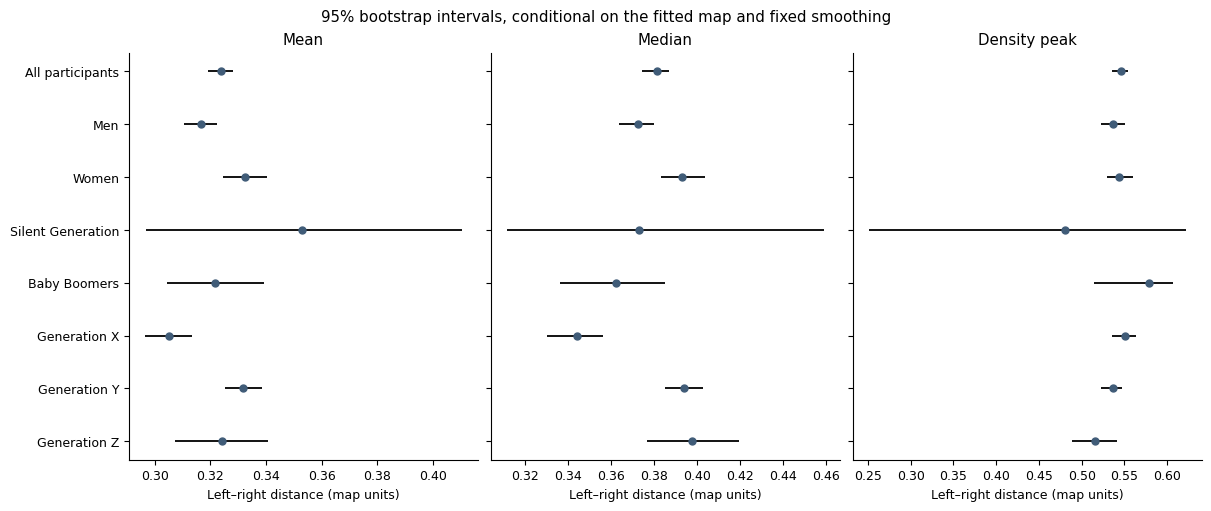

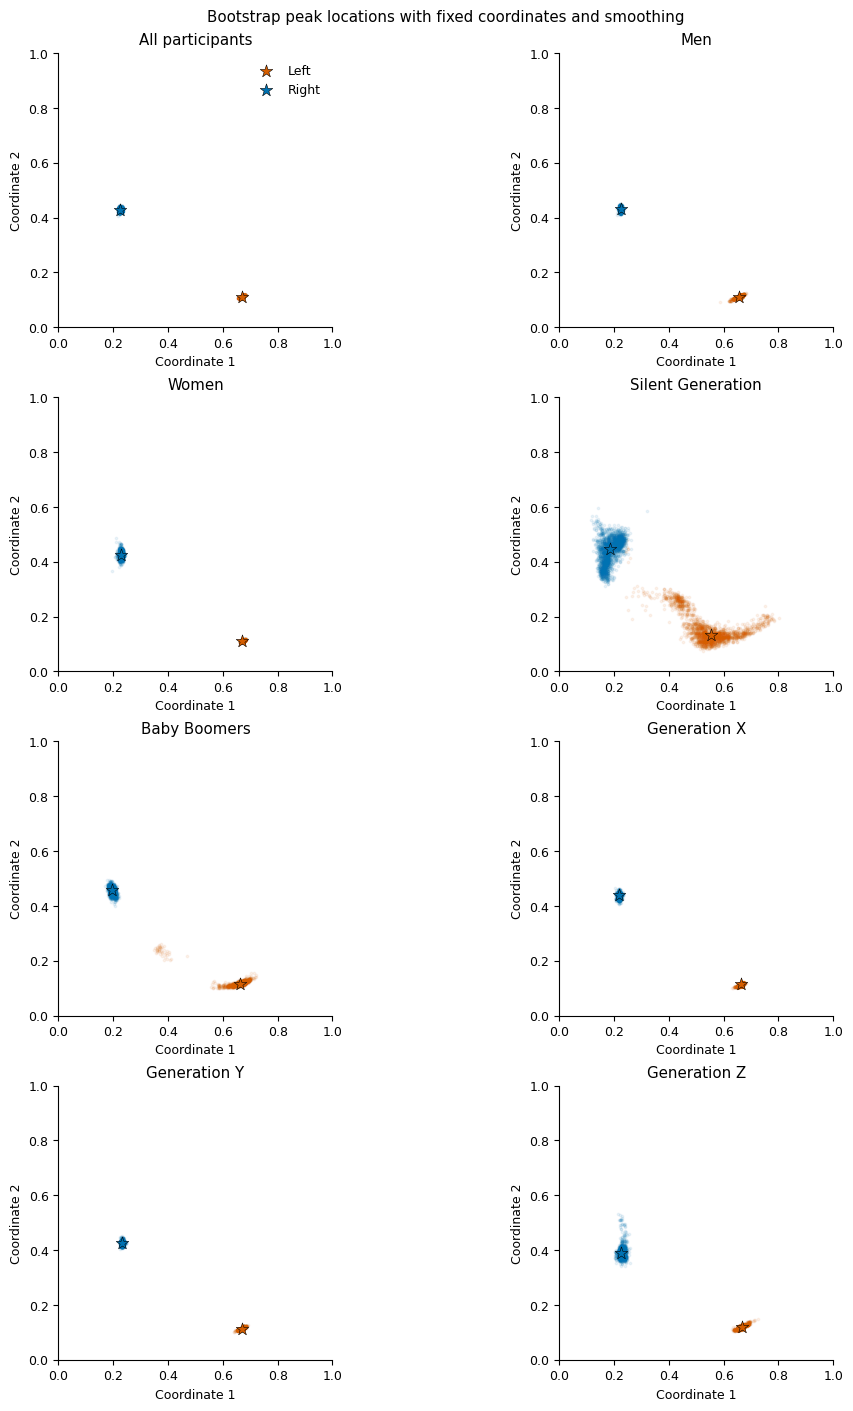

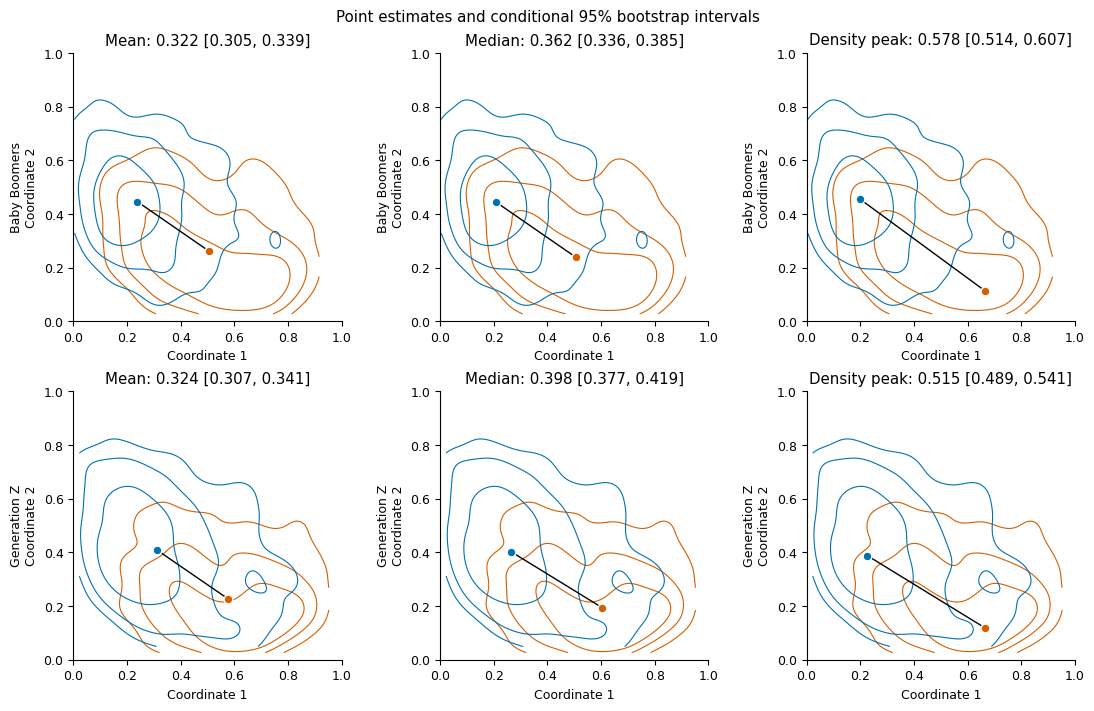

In [6]:
fig, axes = plt.subplots(1,3,figsize=(12,5),sharey=True,layout='constrained')
order = list(groups)
for ax,method in zip(axes,['Mean','Median','Density peak']):
    d = intervals[intervals.summary==method].set_index('group').loc[order]
    y = np.arange(len(d))
    ax.hlines(y,d.lower95,d.upper95,color='black',lw=1.3)
    ax.scatter(d.distance,y,color='#405C78',s=25,zorder=3)
    ax.set(title=method,xlabel='Left–right distance (map units)')
    ax.set_yticks(y,order)
axes[0].invert_yaxis()
fig.suptitle('95% bootstrap intervals, conditional on the fitted map and fixed smoothing')
display(fig)
fig.savefig(OUT/'separation_intervals.pdf',bbox_inches='tight')
fig.savefig(OUT/'separation_intervals.png',dpi=180,bbox_inches='tight')
plt.close(fig)

fig, axes = plt.subplots(4,2,figsize=(10,14),layout='constrained')
for ax,(group,frame) in zip(axes.ravel(),groups.items()):
    for side in ['Left','Right']:
        r=results[(group,side)];p=r['draws']['Density peak']
        ax.scatter(p[:,0],p[:,1],s=3,alpha=.07,color=COLORS[side],rasterized=True)
        ax.scatter(*r['point']['Density peak'],s=90,marker='*',color=COLORS[side],edgecolor='black',lw=.4,label=side,zorder=5)
    ax.set(xlim=(0,1),ylim=(0,1),title=group,xlabel='Coordinate 1',ylabel='Coordinate 2')
    ax.set_aspect('equal')
axes[0,0].legend(frameon=False)
fig.suptitle('Bootstrap peak locations with fixed coordinates and smoothing')
display(fig)
fig.savefig(OUT/'peak_location_clouds.pdf',bbox_inches='tight')
fig.savefig(OUT/'peak_location_clouds.png',dpi=150,bbox_inches='tight')
plt.close(fig)

fig,axes=plt.subplots(2,3,figsize=(11,7),layout='constrained')
for row,group in enumerate(['Baby Boomers','Generation Z']):
    for col,method in enumerate(['Mean','Median','Density peak']):
        ax=axes[row,col]
        for side in ['Left','Right']:
            r=results[(group,side)];v=np.sort(r['density'].ravel())[::-1];c=np.cumsum(v)/v.sum()
            levels=np.unique([v[min(np.searchsorted(c,p),len(v)-1)] for p in [.95,.8,.5]])
            ax.contour(r['gx'],r['gy'],r['density'],levels=levels,colors=[COLORS[side]],linewidths=.8)
            ax.scatter(*r['point'][method],s=40,color=COLORS[side],edgecolor='white',zorder=5)
        pair=np.vstack([results[(group,side)]['point'][method] for side in ['Left','Right']])
        ax.plot(pair[:,0],pair[:,1],color='black',lw=1)
        d=intervals[(intervals.group==group)&(intervals.summary==method)].iloc[0]
        ax.set(title=f'{method}: {d.distance:.3f} [{d.lower95:.3f}, {d.upper95:.3f}]',
               xlim=(0,1),ylim=(0,1),xlabel='Coordinate 1',ylabel=group+'\nCoordinate 2')
        ax.set_aspect('equal')
fig.suptitle('Point estimates and conditional 95% bootstrap intervals')
display(fig)
fig.savefig(OUT/'fig4_with_conditional_intervals.pdf',bbox_inches='tight')
fig.savefig(OUT/'fig4_with_conditional_intervals.png',dpi=180,bbox_inches='tight')
plt.close(fig)

## Verificación y procedencia

Los errores numéricos se comparan con SciPy. Los estimadores puntuales deben
reproducir la tabla anterior antes de producir intervalos. Todos los objetos se
muestran en el notebook y luego se guardan. El manifiesto registra entradas,
parámetros, versiones y salidas para evitar mezclar esta corrida con otros mapas.

Referencia metodológica: Romano (1988), *Bootstrapping the Mode*,
[Annals of the Institute of Statistical Mathematics](https://www.ism.ac.jp/editsec/aism/40/565.pdf).
La advertencia sobre el bootstrap de modas justifica limitar la interpretación a
incertidumbre condicional del mapa suavizado, sin afirmar cobertura poblacional.

In [7]:
verification = pd.DataFrame([
    {'check':'published_point_estimates_reproduced','passed':True},
    {'check':'kernel_density_matches_scipy','passed':bool((diagnostics.scipy_density_max_error<1e-9).all())},
    {'check':'bootstrap_density_matches_direct_mixture','passed':bool((diagnostics.direct_bootstrap_density_error<1e-9).all())},
    {'check':'participant_ids_unique_in_each_input','passed':True},
    {'check':'no_boundary_peaks_in_primary_bootstrap','passed':bool((diagnostics.boundary_fraction==0).all())},
])
display(verification)
verification.to_csv(OUT/'verification.csv',index=False)
manifest = {'n_boot':N_BOOT,'seed':SEED,'grid_size':GRID_SIZE,'kernel':'Gaussian',
            'bandwidth':'Scott covariance fixed within each group/side',
            'bandwidth_multipliers':BANDWIDTH_MULTIPLIERS,'fixed_embeddings':True,
            'interpretation':'pointwise conditional bootstrap percentile intervals, not population-mode or embedding uncertainty',
            'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,
            'input_hashes':source_manifest['files'],
            'outputs':{p.name:sha(p) for p in sorted(OUT.iterdir()) if p.suffix in ['.csv','.pdf','.png']}}
display(manifest)
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')

Out[7]: 2665


,check,passed
0,published_point_estimates_reproduced,True
1,kernel_density_matches_scipy,True
2,bootstrap_density_matches_direct_mixture,True
3,participant_ids_unique_in_each_input,True
4,no_boundary_peaks_in_primary_bootstrap,True


{'n_boot': 2000,
 'seed': 20261013,
 'grid_size': 200,
 'kernel': 'Gaussian',
 'bandwidth': 'Scott covariance fixed within each group/side',
 'bandwidth_multipliers': [0.8, 1.0, 1.25],
 'fixed_embeddings': True,
 'interpretation': 'pointwise conditional bootstrap percentile intervals, not population-mode or embedding uncertainty',
 'numpy': '1.26.4',
 'pandas': '2.3.3',
 'scipy': '1.13.1',
 'input_hashes': {'Chile_overall_participants.csv': {'sha256': '318c2751c3ce8f7bf5ebd0ca967f0f03b70a326dfb2006288b7c1cb47320e720',
   'source': 'outputs/tables/spatial/Chile_overall_participants.csv'},
  'Chile_sex_participants.csv': {'sha256': 'a806b0565358fef4ed37ba548ea5418fc72de7cfe9a4467d78f7b26636fcc678',
   'source': 'outputs/tables/spatial/Chile_sex_participants.csv'},
  'Chile_cohort_participants.csv': {'sha256': 'b6a1f8bfd94c6cd18ec6bb71528158aec5802b721d415a0b87722c2efe3bf786',
   'source': 'outputs/tables/spatial/Chile_cohort_participants.csv'},
  'separation_summaries.csv': {'sha256': 'f

## Figuras del manuscrito con intervalos condicionales

Se conservan los contornos de Scott, los puntos, los colores y el diseño de las figuras originales. Los intervalos se toman de los objetos calculados arriba. Se exportan la comparación Baby Boomers–Generation Z y las separaciones total, por sexo y por cohorte.

In [8]:
from io import BytesIO
from collections import Counter
import fitz
from IPython.display import SVG

FIGURES = ROOT / 'outputs/figures/current'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,
    'axes.spines.top':False,'axes.spines.right':False,'pdf.fonttype':42,
    'figure.facecolor':'white','savefig.facecolor':'white'})
STYLES={'Left':'-','Right':'--'}
CONTOUR_MASSES=[0.95,0.80,0.50]
DENSITY_FILL_ALPHA=0.07
interval_table = intervals.set_index(['group','summary'])
assert interval_table.index.is_unique


In [9]:
def density_and_summaries(frame):
    """Fit the group KDE and return its grid, mean, median, and unique peak."""
    xy = frame[["z2", "z1"]].to_numpy().T
    assert xy.shape[1] >= 3
    kde = gaussian_kde(xy, bw_method="scott")
    gx, gy = np.mgrid[xy[0].min() : xy[0].max() : 200j, xy[1].min() : xy[1].max() : 200j]
    density = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
    peak_index = np.unravel_index(np.argmax(density), density.shape)
    assert all(0 < p < 199 for p in peak_index), ("boundary peak", peak_index)
    assert np.count_nonzero(density == density[peak_index]) == 1
    assert density[peak_index] > np.percentile(density, 90)
    summary = {
        "Mean": xy.mean(axis=1),
        "Median": np.median(xy, axis=1),
        "Density peak": np.array([gx[peak_index], gy[peak_index]]),
    }
    return {
        "x": gx,
        "y": gy,
        "density": density,
        "summaries": summary,
        "n": xy.shape[1],
        "bandwidth_factor": float(kde.factor),
    }


def draw_density(ax, result, side):
    """Draw fixed probability-mass contours from an already fitted density."""
    # Iso-proportion contour levels show the same fitted Gaussian density.
    values = np.sort(result["density"].ravel())[::-1]
    cumulative = np.cumsum(values) / values.sum()
    thresholds = np.unique(
        [
            values[min(np.searchsorted(cumulative, p), len(values) - 1)]
            for p in CONTOUR_MASSES
        ]
    )
    ax.contourf(
        result["x"],
        result["y"],
        result["density"],
        levels=[thresholds[0], result["density"].max() * (1 + 1e-8)],
        colors=[COLORS[side]],
        alpha=DENSITY_FILL_ALPHA,
    )
    ax.contour(
        result["x"],
        result["y"],
        result["density"],
        levels=thresholds,
        colors=[COLORS[side]],
        linestyles=STYLES[side],
        linewidths=np.linspace(0.55, 1.1, len(thresholds)),
        alpha=0.85,
    )


groups={'All participants':overall,'Men':sex[sex.sex=='Masculino'],'Women':sex[sex.sex=='Femenino']}
groups.update({g:cohort[cohort.cohort==g] for g in COHORTS})
densities={g:{s:density_and_summaries(f[f.side==s]) for s in ['Left','Right']} for g,f in groups.items()}

def summary_figure(group_names):
    fig, axes = plt.subplots(
        len(group_names),
        3,
        figsize=(11, 3.2 * len(group_names)),
        squeeze=False,
        layout="constrained",
    )
    for row, group in enumerate(group_names):
        for column, method in enumerate(["Mean", "Median", "Density peak"]):
            ax = axes[row, column]
            for side in ["Left", "Right"]:
                draw_density(ax, densities[group][side], side)
            left = densities[group]["Left"]["summaries"][method]
            right = densities[group]["Right"]["summaries"][method]
            ax.plot([left[0], right[0]], [left[1], right[1]], color="black", lw=1.2, zorder=5)
            ax.scatter(
                *left, color=COLORS["Left"], marker="o", edgecolor="white", s=48, zorder=6
            )
            ax.scatter(
                *right, color=COLORS["Right"], marker="s", edgecolor="white", s=48, zorder=6
            )
            distance = np.linalg.norm(left - right)
            ci = interval_table.loc[(group, method)]
            assert abs(distance-ci.distance) < 1e-12
            assert densities[group]["Left"]["n"] == ci.n_left
            assert densities[group]["Right"]["n"] == ci.n_right
            ax.text(0.04, 0.95, f"{method}: {distance:.2f}", transform=ax.transAxes, va="top")
            ax.text(0.04, 0.885, f"95%: [{ci.lower95:.3f}, {ci.upper95:.3f}]",
                    transform=ax.transAxes, va="top", fontsize=9)
            ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Coordinate 1")
            ax.set_ylabel((group + "\n" if column == 0 else "") + "Coordinate 2")
            ax.set_aspect("equal", adjustable="box")
    return fig



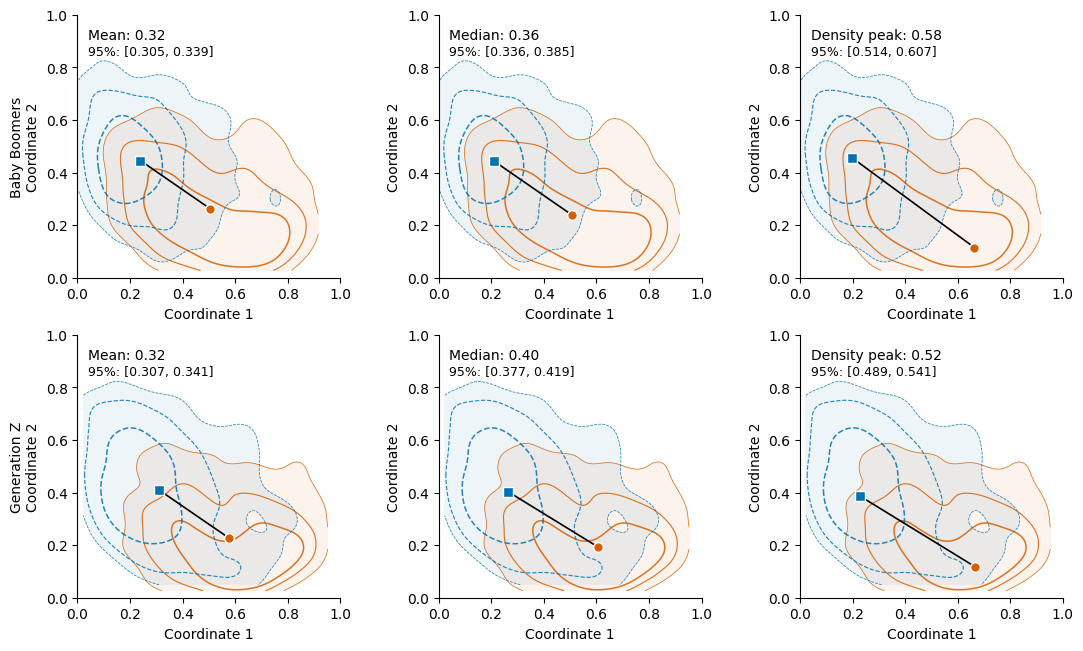

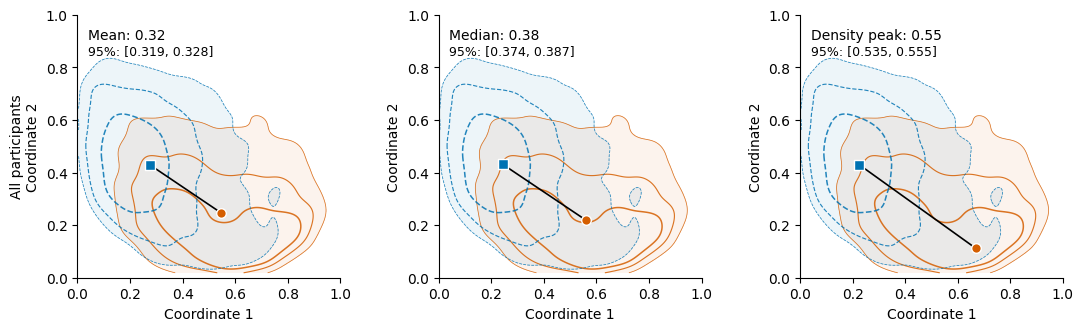

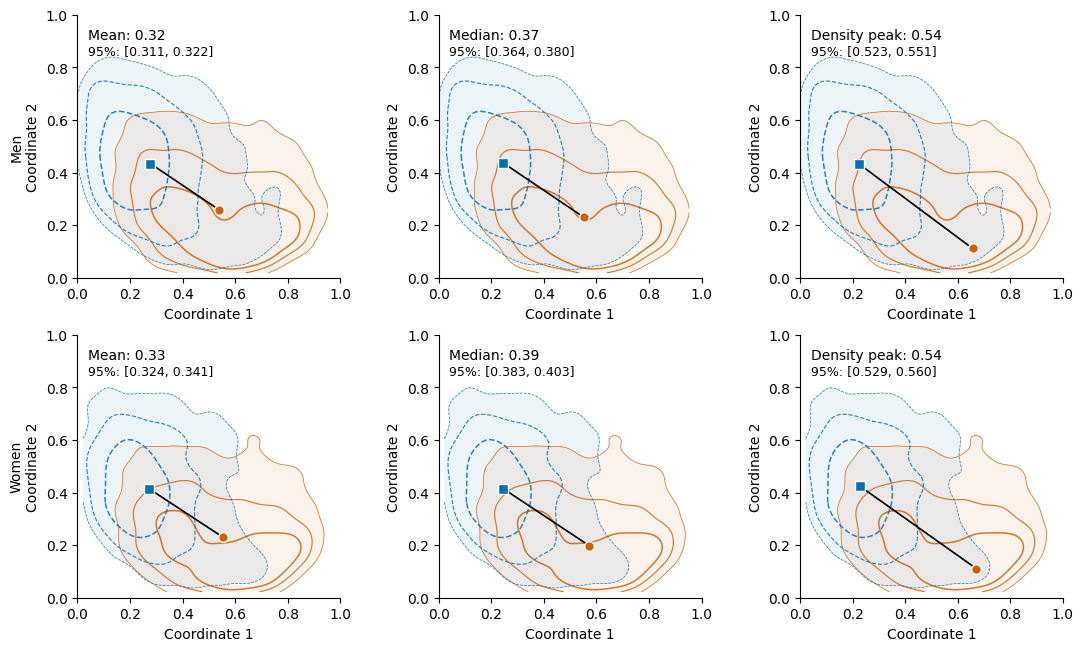

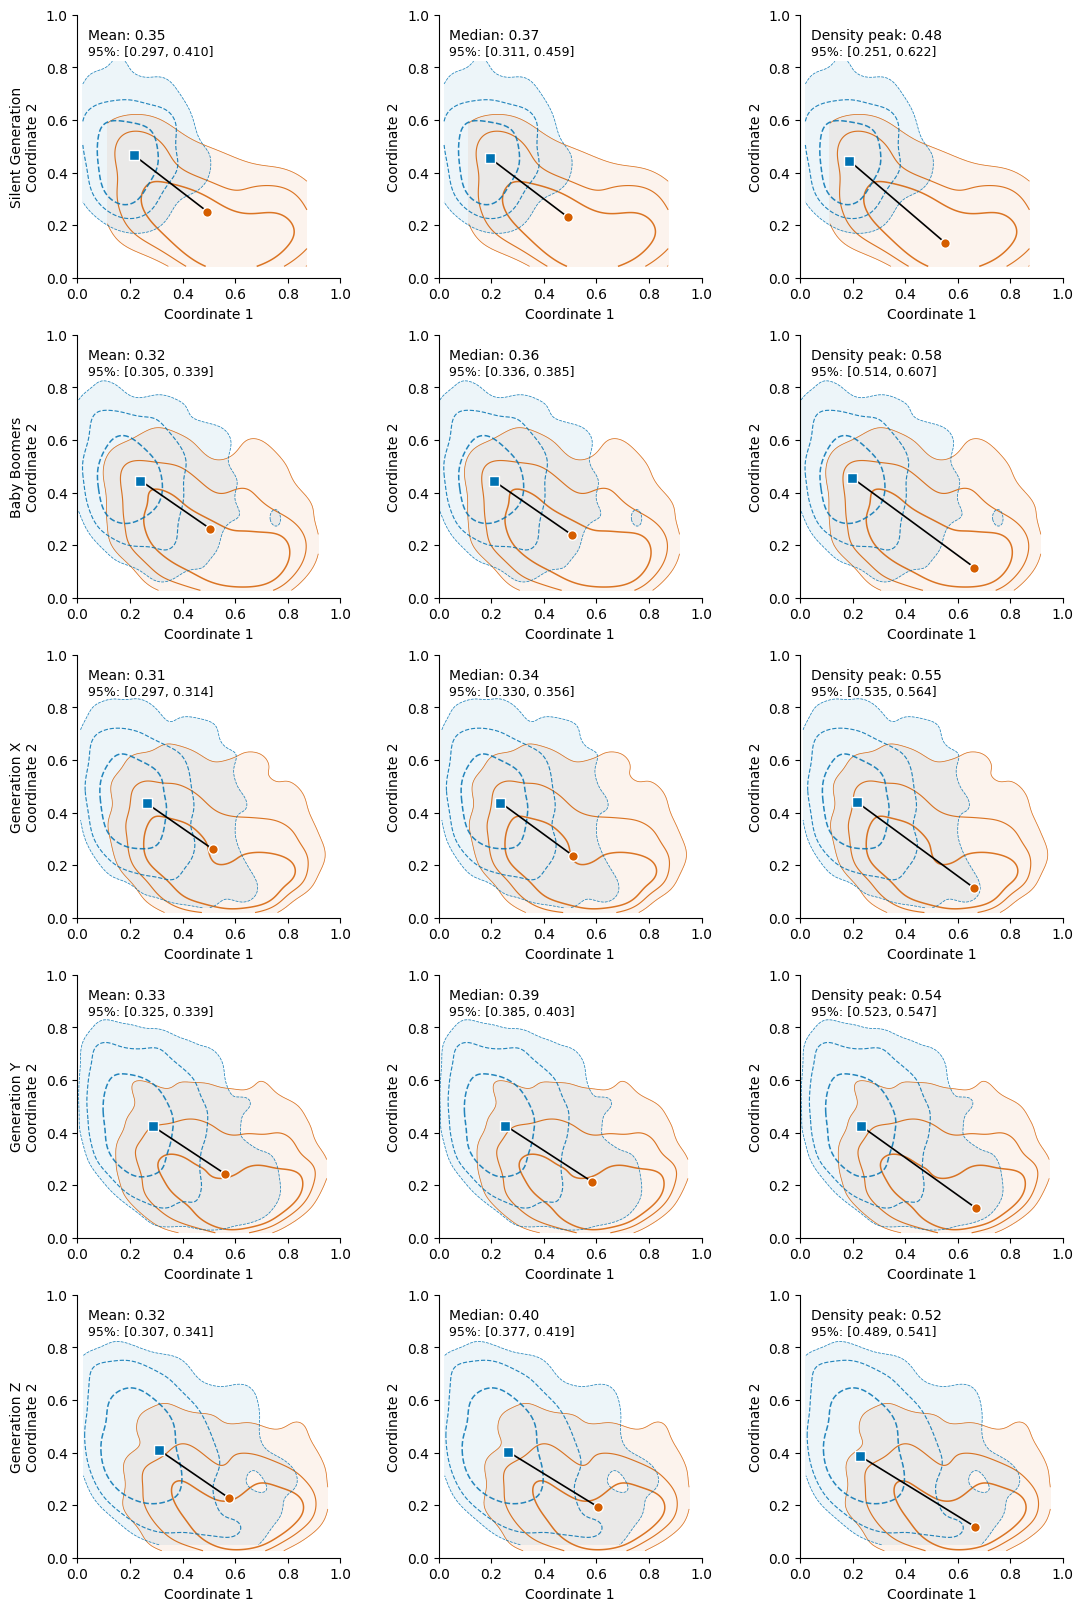

In [10]:
figure_files = {}
current_cohort_pdf = None
for filename, names in [
    ('Fig4', ['Baby Boomers', 'Generation Z']),
    ('FigS11_Overall-Separation', ['All participants']),
    ('FigS12_Separation-by-Sex', ['Men', 'Women']),
    ('FigS13_Separation-by-Cohort', COHORTS),
]:
    fig = summary_figure(names)
    display(fig)
    pdf_buffer = BytesIO()
    fig.savefig(pdf_buffer, format='pdf', bbox_inches='tight', metadata={'CreationDate':None})
    pdf_bytes = pdf_buffer.getvalue()
    path = FIGURES / (filename + '.pdf')
    path.write_bytes(pdf_bytes)
    figure_files[path.name] = sha(path)
    path = FIGURES / (filename + '.png')
    fig.savefig(path, bbox_inches='tight', dpi=170)
    figure_files[path.name] = sha(path)
    if filename == 'Fig4':
        current_cohort_pdf = pdf_bytes
    plt.close(fig)


## Composición de la figura principal

La figura principal combina las distribuciones PC1 por país del notebook 13 con las comparaciones por edad recién generadas. La composición mantiene los paneles vectoriales y verifica que no se pierda ningún texto. El SVG mostrado se genera desde la página compuesta en memoria.

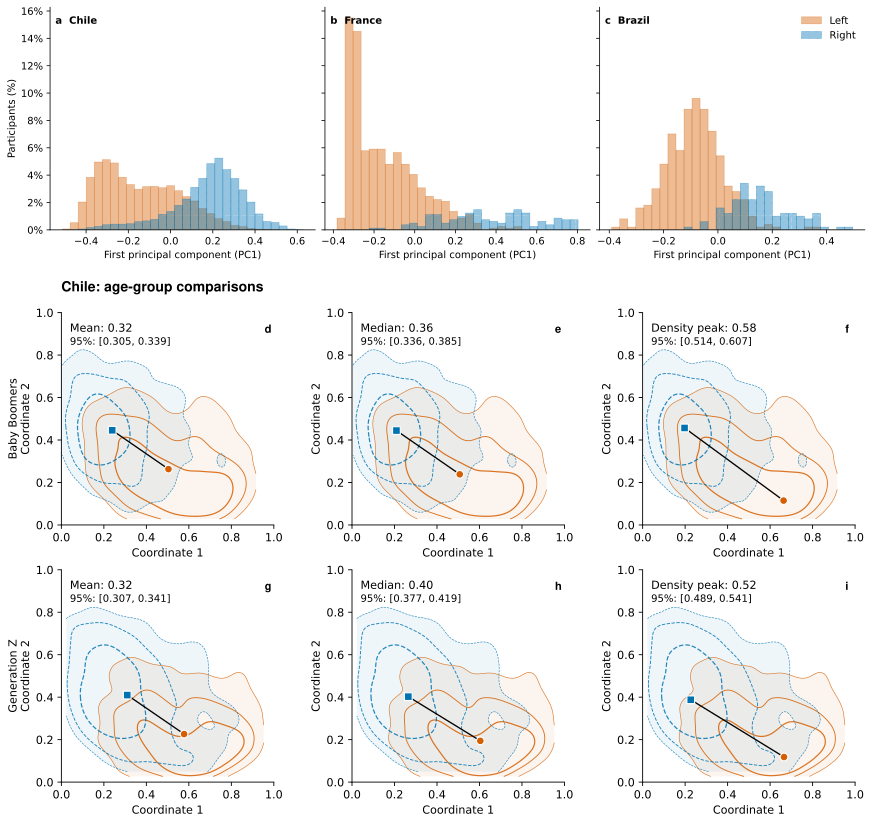

{'inputs': {'Chile_overall_participants.csv': {'sha256': '318c2751c3ce8f7bf5ebd0ca967f0f03b70a326dfb2006288b7c1cb47320e720',
   'source': 'outputs/tables/spatial/Chile_overall_participants.csv'},
  'Chile_sex_participants.csv': {'sha256': 'a806b0565358fef4ed37ba548ea5418fc72de7cfe9a4467d78f7b26636fcc678',
   'source': 'outputs/tables/spatial/Chile_sex_participants.csv'},
  'Chile_cohort_participants.csv': {'sha256': 'b6a1f8bfd94c6cd18ec6bb71528158aec5802b721d415a0b87722c2efe3bf786',
   'source': 'outputs/tables/spatial/Chile_cohort_participants.csv'},
  'separation_summaries.csv': {'sha256': 'ffeda7c69ad2982c02b9c9c4d7aa5e1d56ecce3fc55759961f728c3f823e0e26',
   'source': 'outputs/tables/spatial/separation_summaries.csv'}},
 'country_pc1_panel_sha256': 'bf98eca70afbab875cf582009132621b014484ab8e216c60463427324849ac0b',
 'intervals_sha256': '6282e0ff70b89f6c812eda0296d20cb545bbe333244720e5a8612c86d8f3d01f',
 'output_sha256': {'Fig4.pdf': 'de5bc5d0ddec04be454f241a678fd630ffa2049ec785434be

In [11]:
# The country PC1 panels are supplied by notebook 13. The cohort panels
# are the live vector figure generated above, kept in memory for composition.
source_path = ROOT / 'outputs/figures/Fig3.pdf'
top_document = fitz.open(source_path)
bottom_document = fitz.open(stream=current_cohort_pdf, filetype='pdf')
top, bottom = top_document[0], bottom_document[0]
width = top.rect.width
scale = width / bottom.rect.width
gap = 33.0
bottom_y = top.rect.height + gap
height = bottom_y + bottom.rect.height * scale
combined = fitz.open()
page = combined.new_page(width=width, height=height)
page.draw_rect(page.rect, color=None, fill=(1,1,1), overlay=False)
page.show_pdf_page(fitz.Rect(0,0,width,top.rect.height), top_document, 0)
page.show_pdf_page(fitz.Rect(0,bottom_y,width,height), bottom_document, 0)
page.insert_text((54.9*scale, top.rect.height+24),
                 'Chile: age-group comparisons', fontname='hebo', fontsize=14)
for letter, x, y in [
    ('d',237,29), ('e',497,29), ('f',757,29),
    ('g',237,259.4), ('h',497,259.4), ('i',757,259.4),
]:
    page.insert_text((x*scale,bottom_y+y*scale), letter,
                     fontname='hebo', fontsize=10*scale)
expected_words = Counter(top.get_text().split()) + Counter(bottom.get_text().split())
assert not (expected_words - Counter(page.get_text().split()))
assert not page.get_images(), 'The composition must preserve vector panels.'
# SVG is generated from the live composed page before exporting its PDF.
svg_from_page = page.get_svg_image
display(SVG(svg_from_page()))
combined.set_metadata({'title':'DYNAMAP Figure 3','author':'',
    'subject':'Country PC1 distributions and conditional age-group intervals'})
path = FIGURES / 'Fig3_combined.pdf'
combined.save(path, garbage=4, deflate=True, no_new_id=True)
figure_files[path.name] = sha(path)
figure_manifest = {
    'inputs': source_manifest['files'],
    'country_pc1_panel_sha256': sha(source_path),
    'intervals_sha256': sha(OUT/'separation_intervals.csv'),
    'output_sha256': figure_files,
    'all_source_text_tokens_preserved': True,
    'raster_images_in_composition': len(page.get_images()),
}
display(figure_manifest)
(FIGURES/'interval_figures_manifest.json').write_text(json.dumps(figure_manifest,indent=2)+'\n')
combined.close()
top_document.close()
bottom_document.close()
